<a href="https://colab.research.google.com/github/XanderPatterson/4487-IS-Class-Labs/blob/main/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`)
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [31]:
df = pd.read_csv('adviseinvest_historical_data (1).csv')

print(df.info())
print(df.head())
print(df.describe())

print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB
None
   customer_id  answered  income female  age  job  num_dep

### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. The initial data preview shows a few unusual issues: negative income values (down to -65,600), an unrealistic age of 132, an outlier in the number of accounts (3,345), 2 missing values in new_car, and 3 duplicate rows. The female column is formatted as an object instead of a numeric type.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [32]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

df_clean = df_clean.dropna(subset=['new_car'])

df_clean = df_clean[(df_clean['income'] >= 0) & (df_clean['age'] <= 100)]

df_clean = df_clean.drop(columns=['customer_id', 'product'])

df_clean['answered'] = df_clean['answered'].astype(int)

if df_clean['female'].dtype == 'object':
    df_clean['female'] = df_clean['female'].astype(str).str.strip().map({'1': 1, '0': 0, 'F': 1, 'M': 0}).fillna(0).astype(int)
else:
    df_clean['female'] = df_clean['female'].astype(int)

print(df_clean.info())

<class 'pandas.core.frame.DataFrame'>
Index: 29496 entries, 1 to 29503
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   answered        29496 non-null  int64  
 1   income          29496 non-null  int64  
 2   female          29496 non-null  int64  
 3   age             29496 non-null  int64  
 4   job             29496 non-null  int64  
 5   num_dependents  29496 non-null  int64  
 6   rent            29496 non-null  int64  
 7   own_res         29496 non-null  int64  
 8   new_car         29496 non-null  float64
 9   chk_acct        29496 non-null  int64  
 10  sav_acct        29496 non-null  int64  
 11  num_accts       29496 non-null  int64  
 12  mobile          29496 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 3.2 MB
None


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I removed customer id because it is just a unique identifier, and product because it is determined after the phone call happens and would cause data leakage.

2.6 I removed negative incomes, account outliers (over 3,345), and ages above 100 because they were data entry errors. I also dropped rows with missing values in new car since they made up a tiny part of the data.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [33]:
df_clean['answered'] = df_clean['answered'].astype(bool)

## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [34]:
cat_cols = ['job', 'chk_acct', 'sav_acct']
for col in cat_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype('category')

print(df_clean.dtypes)

answered              bool
income               int64
female               int64
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car            float64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



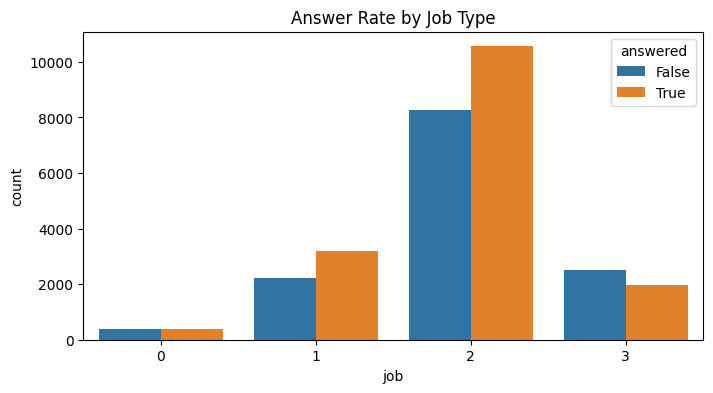

In [35]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df_clean, x='job', hue='answered')
plt.title('Answer Rate by Job Type')
plt.show()

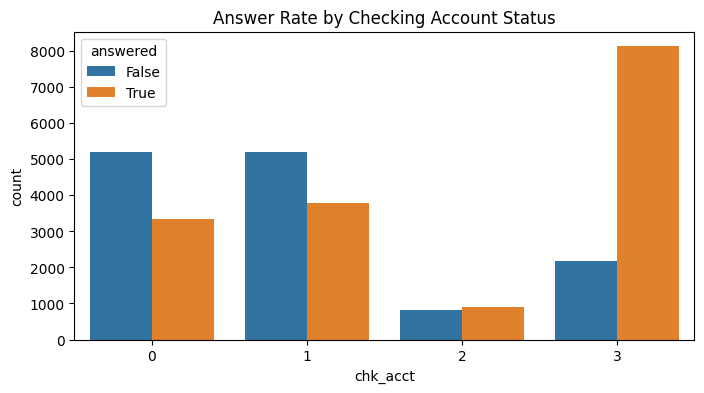

In [36]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df_clean, x='chk_acct', hue='answered')
plt.title('Answer Rate by Checking Account Status')
plt.show()

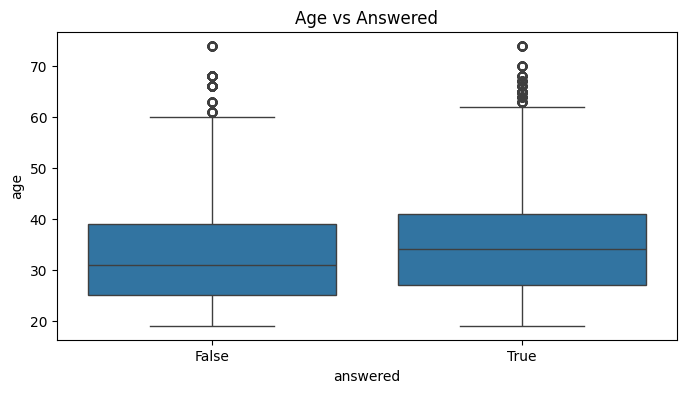

In [37]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_clean, x='answered', y='age')
plt.title('Age vs Answered')
plt.show()

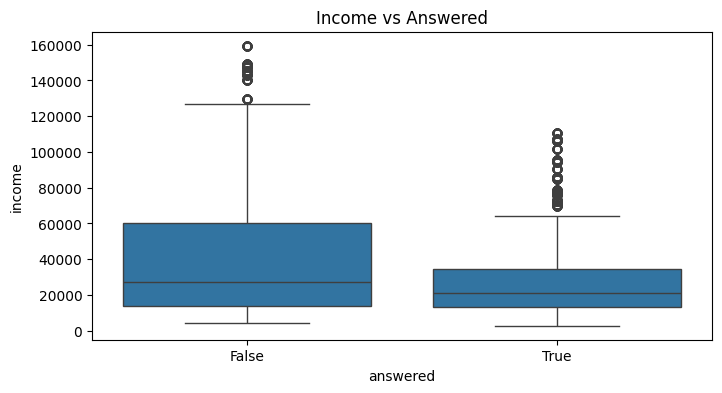

In [38]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_clean, x='answered', y='income')
plt.title('Income vs Answered')
plt.show()

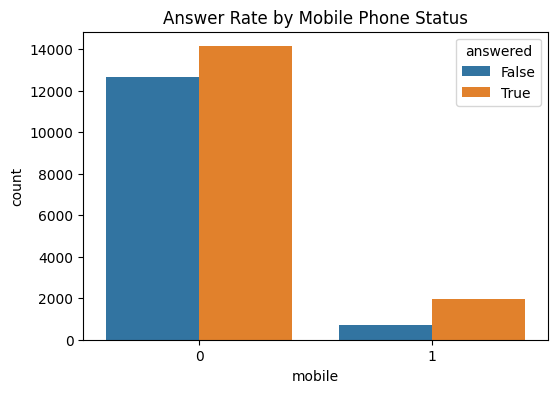

In [39]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='mobile', hue='answered')
plt.title('Answer Rate by Mobile Phone Status')
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Checking account status, savings account balance, and job type show the strongest relationships with a customer answering the call.

3.7. Variables like mobile and rent show very weak relationships with the target variable, but we don't need to remove them since tree models can automatically select the most important features.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [40]:
base_prob = df_clean['answered'].mean()
print(f"Base Probability of Answering: {base_prob:.4f}")

Base Probability of Answering: 0.5467


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [41]:
from sklearn.model_selection import train_test_split

X = pd.get_dummies(df_clean.drop(columns=['answered']), drop_first=True)
y = df_clean['answered']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Training features shape: (23596, 19)
Testing features shape: (5900, 19)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

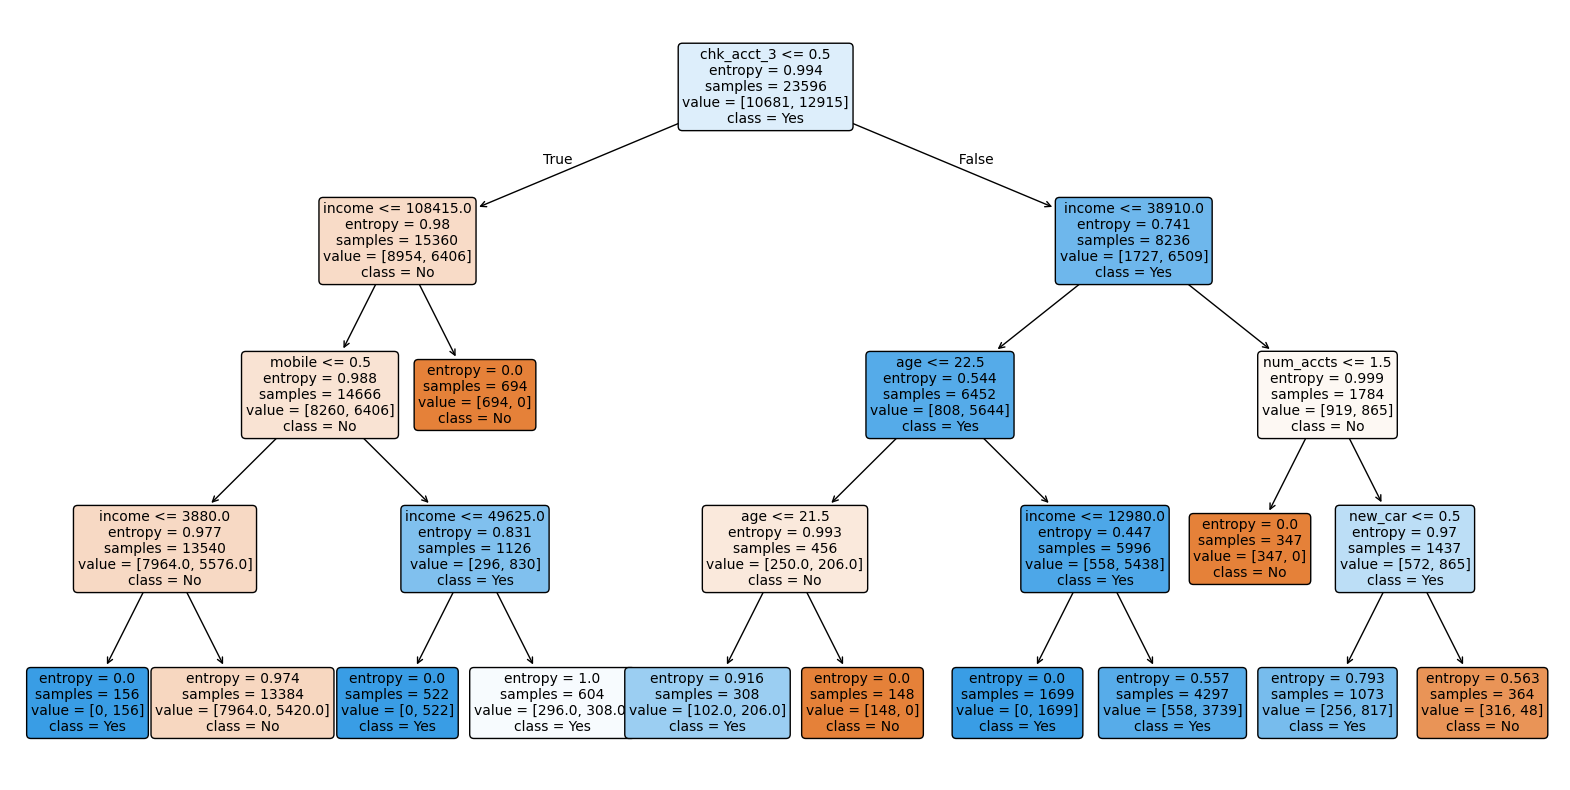

In [42]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dtree = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dtree.fit(X_train, y_train)

plt.figure(figsize=(20, 10))
plot_tree(dtree, feature_names=X.columns, class_names=['No', 'Yes'], filled=True, rounded=True, fontsize=10)
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [43]:
from sklearn.metrics import accuracy_score

y_pred = dtree.predict(X_test)

tree_accuracy = accuracy_score(y_test, y_pred)
print(f"Decision Tree Accuracy: {tree_accuracy:.4f}")

Decision Tree Accuracy: 0.7112


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The decision tree model accuracy is about 71.1%, and it improved compared to the last probabilty of 54.7%.

2. Yes, this increase helps the business better target customers who will actually pick up the phone, reducing wasted time and staffing problems.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [44]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[2366  324]
 [1380 1830]]


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

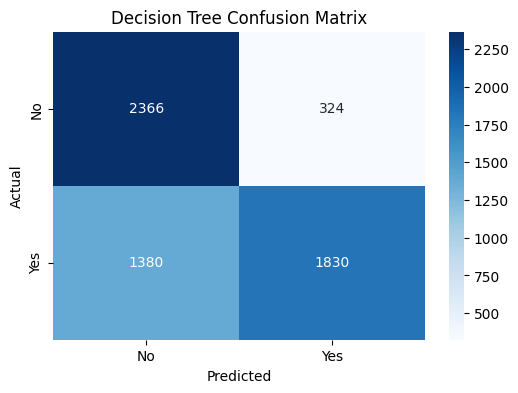

In [45]:
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree Confusion Matrix')
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [46]:
true_positives = cm[1, 1]
false_positives = cm[0, 1]

model_profit = (true_positives * 75) - (false_positives * 25)
print(f"Model Profit: ${model_profit:,.2f}")

Model Profit: $129,150.00


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [47]:
total_actual_answered = y_test.sum()
total_actual_not_answered = len(y_test) - total_actual_answered

default_profit = (total_actual_answered * 75) - (total_actual_not_answered * 25)
print(f"Default Profit (Calling Everyone): ${default_profit:,.2f}")
print(f"Profit Difference: ${model_profit - default_profit:,.2f}")

Default Profit (Calling Everyone): $173,500.00
Profit Difference: $-44,350.00


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling everyone generated $173,500, with the decision tree model resulting in a profit of $129,150 making the model's profit $44,350 lower.

2. Yes, this is a significant difference because filtering left out some actual buyers due to false negatives, meaning the default strategy currently brings in more net profit for the business.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [48]:
dtree_tuned = DecisionTreeClassifier(criterion='entropy', max_depth=6, random_state=42)
dtree_tuned.fit(X_train, y_train)

y_pred_tuned = dtree_tuned.predict(X_test)
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
print(f"Tuned Decision Tree Accuracy: {tuned_accuracy:.4f}")

Tuned Decision Tree Accuracy: 0.7597


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [49]:
df_new = pd.read_csv('adviseinvest_new_customer_data.csv')

df_new_clean = df_new.copy()
df_new_clean = df_new_clean.drop_duplicates()
df_new_clean = df_new_clean.dropna(subset=['new_car'])
df_new_clean = df_new_clean[(df_new_clean['income'] >= 0) & (df_new_clean['age'] <= 100)]

cols_to_drop = [col for col in ['customer_id', 'product'] if col in df_new_clean.columns]
df_new_clean = df_new_clean.drop(columns=cols_to_drop)

if 'female' in df_new_clean.columns and df_new_clean['female'].dtype == 'object':
    df_new_clean['female'] = df_new_clean['female'].astype(str).str.strip().map({'1': 1, '0': 0, 'F': 1, 'M': 0}).fillna(0).astype(int)

cat_cols = ['job', 'chk_acct', 'sav_acct']
for col in cat_cols:
    if col in df_new_clean.columns:
        df_new_clean[col] = df_new_clean[col].astype('category')

X_new = pd.get_dummies(df_new_clean, drop_first=True)
X_new = X_new.reindex(columns=X.columns, fill_value=0)

new_predictions = dtree_tuned.predict(X_new)

num_yes = (new_predictions == 1).sum()
num_no = (new_predictions == 0).sum()

print(f"Predicted to Answer (Yes): {num_yes}")
print(f"Predicted Not to Answer (No): {num_no}")

Predicted to Answer (Yes): 366
Predicted Not to Answer (No): 634


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 While the first decision tree reduced profit compared to calling everyone due to having false negatives, the model's accuracy improved with tuning (reaching about 76%), allowing the business to better pinpoint higher probability customers and avoid wasted staffing efforts.

6.2 The business can utilize this model to prioritize sales reps' outgoing call lists, focusing time and resources only on customers who are predicted to answer, this will reduce downtime and staffing inefficiencies going forward while focusing on the higher probability customers.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [51]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 827843 bytes to assignment_10_classification.html
